In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [2]:
train_url = "http://ufldl.stanford.edu/housenumbers/train_32x32.mat"
test_url = "http://ufldl.stanford.edu/housenumbers/test_32x32.mat"
print("Downloading SVHN dataset")
path_train = tf.keras.utils.get_file('train_32x32.mat', train_url)
path_test = tf.keras.utils.get_file('test_32x32.mat', test_url)
def load_svhn_data(path):
    data = sio.loadmat(path)
    X = data['X']
    y = data['y']
    X = np.transpose(X, (3, 0, 1, 2))

    y[y == 10] = 0
    return X, y
X_train_full, y_train_full = load_svhn_data(path_train) #raw data
X_test, y_test = load_svhn_data(path_test)

print("Loading data successful")

182040794/182040794 ━━━━━━━━━━━━━━━━━━━━ 33s 0us/step
64275384/64275384 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
Loading data successful


Reshaping: The code rearranges the raw image data from the MATLAB format (Height, Width, Channels, Count) into the standard TensorFlow format (Count, Height, Width, Channels) so the model can process it.

Label Fixing: It corrects the dataset's specific quirk where the digit '0' is labeled as '10' by changing all 10s back to 0s, ensuring the classes range correctly from 0 to 9.

In [3]:
X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42)
print("preprocessing done")

preprocessing done


**Appropriate data preprocessing**
#1. Resizing and  Reshaping

I already reshaped dimensions to (N, 32, 32, 3) in the loading stepp, and the images are 32x32, which is a standard size for CNNs

# 2. Normalization
I scaled pixel values from 0-255 to the range 0-1 for better convergence

#3. Train-validation split
I have split the training data, 90% for trainingand 10% of it for the validation purposes



Training Data Shape: (65931, 32, 32, 3)
Validation Data Shape: (7326, 32, 32, 3)
Test Data Shape: (26032, 32, 32, 3)
Number of classes: 10 (Digits 0-9)

Displaying 5 random sample images:


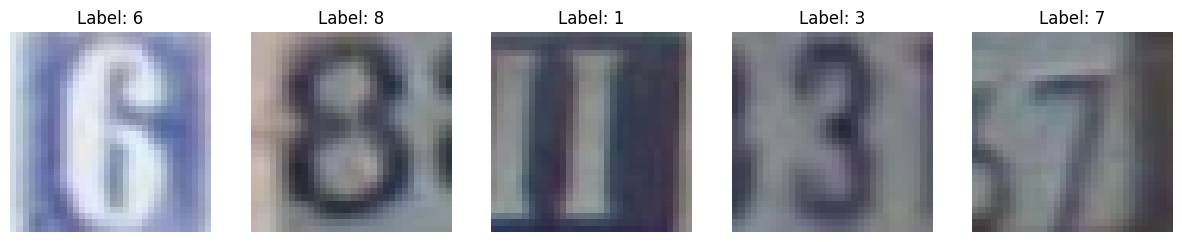

In [4]:
print(f"Training Data Shape: {X_train.shape}")
print(f"Validation Data Shape: {X_val.shape}")
print(f"Test Data Shape: {X_test.shape}")
num_classes = len(np.unique(y_train_full))
print(f"Number of classes: {num_classes} (Digits 0-9)")
print("\nDisplaying 5 random sample images:")
plt.figure(figsize=(15, 3))
indices = np.random.randint(0, len(X_train), 5)
for i, idx in enumerate(indices):
    plt.subplot(1, 5, i+1)
    plt.imshow(X_train[idx])
    plt.title(f"Label: {y_train[idx][0]}")
    plt.axis('off')
plt.show()

#1. Showing Dataset Shape
it will print the size of my data arrays, it is worth ensuring that the shapes are checked to verify that the data was loaded and split properly
#2. Showing Number of Classes
displaying number of nlasses ccans the entire array of labels and creates a list with all the unique values observed, counts the number of unique values.This proved the fact that I am working with a 10-class classification task (digits 0-9) and that is why, my final neural network layer should have 10 neurons.
#3. Showing 5 Labeled Sample Images
np.random.randint(...): This does not simply display the first 5 images (this could be all the same image) but rather selects 5 random numbers that are indexes in my dataset this will guarantee a varied examination of the data each time i will operate the cell


#Question 1: What is the significance of normalization?

 The normalization is a very important preprocessing process that data of the pixel is scaled to a range of 0-255 to 0-1. This is important because:
1. Faster Convergence: It assists the optimization
algorithm (such as Adam or SGD) to converge to the least loss considerably quicker.
2. Gradient Stability: Backpropagation with large input values will cause huge gradients and hence the weights of the model will change in unstable ways (the "exploding gradient" problem).
3Uniformity: It implies that every input feature (pixels) has the same contribution to the learning of the model.

#Question 2: A dataset-specific problem (SVHN?)?
 One of the most significant problems that the SVHN (Street View House Numbers) data has is background noise and distracting numbers.
In contrast to the MNIST database that has single handwritten numbers on a black background, the SVHN images are cut out of actual street photographs.
Usually, a picture with the number 1 on it will have the character 1 in the middle of the picture, only that there will also be part of the number that is on the left or the right sides (such as a number 2 or 3). This noise may end up confusing the CNN to classify the image as per the peripheral digits and not the central one.


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# initializing the sequential model
model = Sequential([ #using sequential to stack layers one after another
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),

    #>= 1 Pooling layer (This is #1)
    MaxPooling2D(pool_size=(2, 2)),

    # Second Convolutional
    Conv2D(64, (3, 3), activation='relu'),

    #>= 1 Pooling layer (This is #2)
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),

    #  >= 1 fully connectedlayer
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

#First Convolutional Block
the initial convolutional block aims at extracting low-level visual features of the input images, i.e. edges, corners and plain textures
the network has two conv2D layers (as needed) to gain a gradual feature representation learning.
the initial conv2D layer has 32 filters and this is enough to identify simple structures at the initial stages of the network.

The kernel size (3x3) is selected since it is a standard and good size of small image like 32x32 pixels.

The input shape is 32, 32, 3; that is, the SVHN dataset images are 32x32 pixel images in tri-color (RGB).

Once this convolution has been done, we then use maxpooling to cut the size of the width and height by half. This helps:
Reduce computational cost
Control overfitting
Maintain the most significant aspects.
**calculation
input dimwnsion /pool size
input image =32x32pixels
first pooling=32/2=16
second pooling 16/2=8**

#Classification Head
After the convolutional layers have identified the important features, the classification head makes the final decision.

The Flatten layer transforms the 2D feature maps to a 1D feature vector making it able to use fully connected (dense) layers.

The extracted features are interpreted in a layer of 128 neurons which learns higher level representations.

During training, there is a dropout (0.5) to randomly disable a half of neurons and this is used to prevent overfitting, and enhances the generalization.
Output Layer

The output layer has ten neurons which are the 10 digit classes (0-9).
#Activation function
A softmax activation function is applied to transform the output to scores of probability, with the total score of all the probabilities being 1.
Multi-class classification problems require the use of softmax because the model can give the most likely classification.

#mandatory justification
**Filters**:I applied 32 filters in the first convolutional layer and 64 filters in the second layer.Rationales:This pyramidal model enables the network to learn gradually. The first 32 filters identify very elementary, low level features (such as horizontal or vertical edges). These are merged using the deeper 64 filters in order to capture more complex and high level features (such as loops, curves and individual shapes of digits).
#2. Kernel sizes:
I selected a 3 x 3 kernel size in all convolutional layers.Rational:A 3 x 3 kernel is the standard in the industry when it comes to classifying images. It is small enough to routinely pick out local detail, yet large enough to pool up the amount of surrounding pixels needed to operate a   computation.
#3 Activation functions:
ReLU (Rectified Linear Unit): I made all the hidden layers to use ReLU. It is also computationally efficient and addresses the problem of the vanishing gradient, which enables the model to successfully learn non-linear patterns.Softmax: Softmax was applied to the final output layer. Multi-class classification (0-9) is obligatory as it transforms the raw outputs of the model (logits) into a probability distribution, which adds up to 1.0.
#4. The reasons why CNN is appropriate in this dataset:
 CNNs (Convolutional Neural Networks) are tailored to grid-shaped data, e.g., images. In contrast to the conventional dense networks (MLPs) which flatten input directly and disregard the spatial structure, CNNs scan the image with the help of convolution. This does not destroy the spatial information between the pixels (e.g., that a pixel is above or beside a different pixel) which is important to realise the structure of digits in the SVHN dataset.

In [7]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
#model training
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=12,
                    batch_size=64)

Epoch 1/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 84s 80ms/step - accuracy: 0.4608 - loss: 1.5910 - val_accuracy: 0.8354 - val_loss: 0.6082
Epoch 2/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 145s 82ms/step - accuracy: 0.7721 - loss: 0.7514 - val_accuracy: 0.8554 - val_loss: 0.4907
Epoch 3/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 141s 81ms/step - accuracy: 0.8046 - loss: 0.6460 - val_accuracy: 0.8658 - val_loss: 0.4562
Epoch 4/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 154s 93ms/step - accuracy: 0.8201 - loss: 0.5929 - val_accuracy: 0.8695 - val_loss: 0.4381
Epoch 5/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 149s 99ms/step - accuracy: 0.8293 - loss: 0.5621 - val_accuracy: 0.8789 - val_loss: 0.4122
Epoch 6/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 94s 91ms/step - accuracy: 0.8400 - loss: 0.5308 - val_accuracy: 0.8789 - val_loss: 0.4198
Epoch 7/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 87s 85ms/step - accuracy: 0.8445 - loss: 0.5067 - val_accuracy: 0.8851 - val_loss: 0.3932
Epoch 8/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 92s 89ms/step - accuracy: 0.85

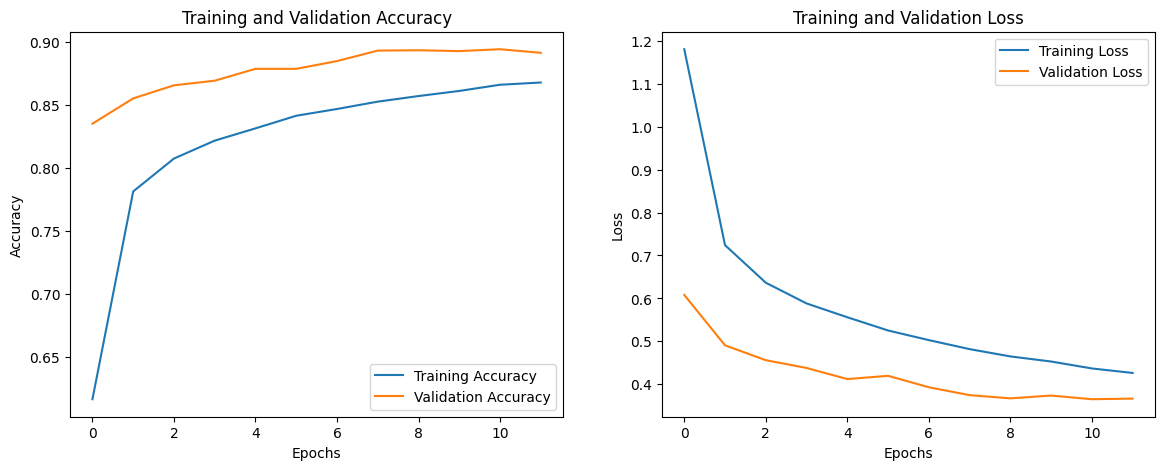

In [8]:
import matplotlib.pyplot as plt
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc)) # ranging from 0 to 11 (for 12 epochs)
plt.figure(figsize=(14, 5))
# accuracy ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
#loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

#overfitting/ underfitting
not overfitting,, nor is it underfitting

 the orange line is (more accurate and less loss) better than the Blue line, This comes about due to the addition of the Dropout(0.5) layer, when the model was being being trained, it is handicapped by dropout, whereas when being used in validation, it operates at full power. This proves that regularization is functioning well.
Early Epochs (0-4): This was the model that was learned at a very rapid rate. The steep drop in loss and steep rise in accuracy can be seen.
Later Epochs (8-11): The curves begin to level off (plateau). It shows that 12 epochs was an ideal figure.

at epoch 5 accurCY WOUld not have been achived(approximately 83 percent vs 89 percent).
 this is a result of  Add Dropout(0.5) layer in Partb

in Training, 50 percent of the neurons are shut off and it is thus difficult to teach the model. Validation activates all the neurons and thus the model operates in full power. This is one of the indicators that regularization policy was a success.

#Evidence from plots:
accuracy Plot The Validation (orange) follows the Training (blue) and even exceeds it throughout the majority of the training, this is a good sign that the model is generalizing and not being trained on the training data (which would appear to be high training accuracy, but low validation accuracy).
loss Plot: the Validation Loss (orange) reduce continuously with the Training Loss (blue) and does not return to a point higher than 0.37. This is indicative of effective learning on the part of the model

In [9]:
model_exp = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])
#  Compile (SGD instead of Adam)
model_exp.compile(optimizer='sgd',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

history_exp = model_exp.fit(X_train, y_train,
                            validation_data=(X_val, y_val),
                            epochs=12,
                            batch_size=64,
                            verbose=1)

val_acc_baseline = max(history.history['val_accuracy'])
val_acc_experiment = max(history_exp.history['val_accuracy'])
print(f"\nResults Comparison:")
print(f"Original Model (Adam) Best Val Accuracy: {val_acc_baseline:.4f}")
print(f"Experimental Model (SGD) Best Val Accuracy: {val_acc_experiment:.4f}")

Epoch 1/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 87s 84ms/step - accuracy: 0.1771 - loss: 2.2525 - val_accuracy: 0.1998 - val_loss: 2.2145
Epoch 2/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 84s 82ms/step - accuracy: 0.1983 - loss: 2.2192 - val_accuracy: 0.2128 - val_loss: 2.1131
Epoch 3/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 142s 81ms/step - accuracy: 0.3045 - loss: 2.0166 - val_accuracy: 0.5753 - val_loss: 1.3793
Epoch 4/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 83s 80ms/step - accuracy: 0.5591 - loss: 1.3698 - val_accuracy: 0.6968 - val_loss: 0.9961
Epoch 5/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 140s 79ms/step - accuracy: 0.6866 - loss: 1.0271 - val_accuracy: 0.7813 - val_loss: 0.7531
Epoch 6/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 83s 80ms/step - accuracy: 0.7352 - loss: 0.8757 - val_accuracy: 0.7781 - val_loss: 0.7531
Epoch 7/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 84s 81ms/step - accuracy: 0.7602 - loss: 0.7957 - val_accuracy: 0.8281 - val_loss: 0.6555
Epoch 8/12
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 82s 79ms/step - accuracy: 0.7807


--- Final Results Comparison ---
Original Model (Adam) Best Val Accuracy: 0.8945
Experimental Model (SGD) Best Val Accuracy: 0.8546


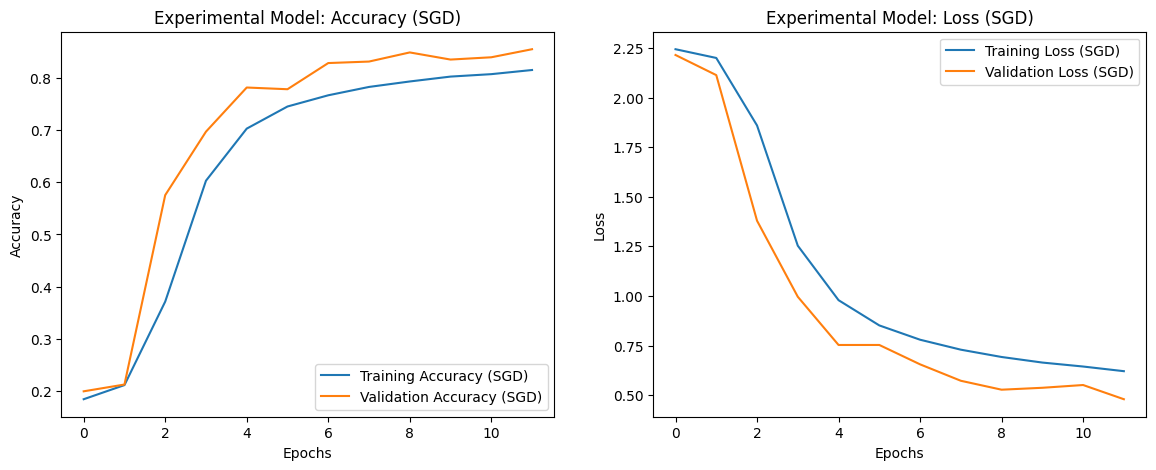

In [10]:
import matplotlib.pyplot as plt
val_acc_baseline = max(history.history['val_accuracy'])
val_acc_experiment = max(history_exp.history['val_accuracy'])

print(f"\n--- Final Results Comparison ---")
print(f"Original Model (Adam) Best Val Accuracy: {val_acc_baseline:.4f}")
print(f"Experimental Model (SGD) Best Val Accuracy: {val_acc_experiment:.4f}")
acc = history_exp.history['accuracy']
val_acc = history_exp.history['val_accuracy']
loss = history_exp.history['loss']
val_loss = history_exp.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(14, 5))

#SGD Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy (SGD)')
plt.plot(epochs_range, val_acc, label='Validation Accuracy (SGD)')
plt.legend(loc='lower right')
plt.title('Experimental Model: Accuracy (SGD)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

#SGD Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss (SGD)')
plt.plot(epochs_range, val_loss, label='Validation Loss (SGD)')
plt.legend(loc='upper right')
plt.title('Experimental Model: Loss (SGD)')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

--- Final Accuracy Comparison ---
Adam Optimizer: 0.8945
SGD Optimizer:  0.8546


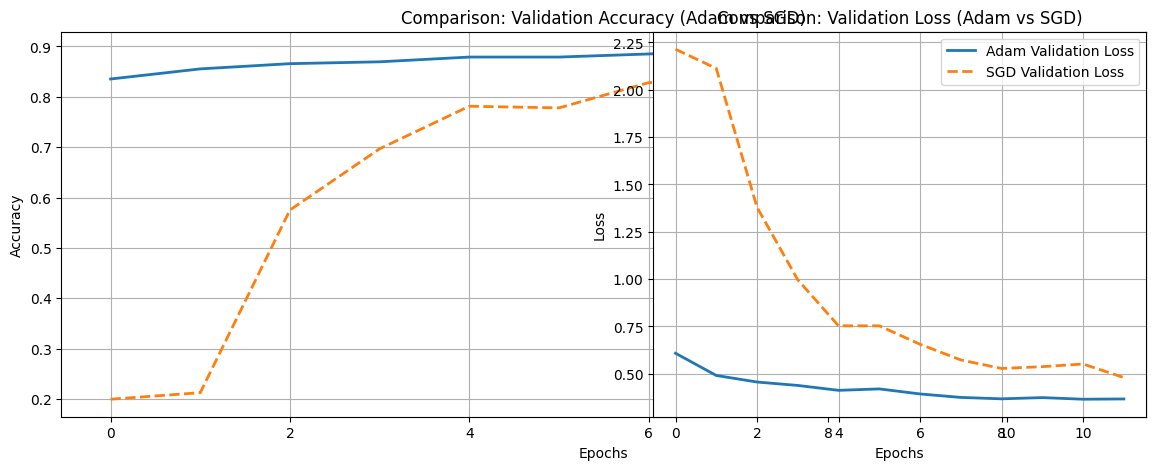

In [11]:
import matplotlib.pyplot as plt
val_acc_adam = max(history.history['val_accuracy'])
val_acc_sgd = max(history_exp.history['val_accuracy'])

print(f"--- Final Accuracy Comparison ---")
print(f"Adam Optimizer: {val_acc_adam:.4f}")
print(f"SGD Optimizer:  {val_acc_sgd:.4f}")
# Adam Data
acc_adam = history.history['val_accuracy']
loss_adam = history.history['val_loss']
# SGD Data
acc_sgd = history_exp.history['val_accuracy']
loss_sgd = history_exp.history['val_loss']
epochs_range = range(len(acc_adam))
plt.figure(figsize=(14, 5))
# Validation Accuracy Comparison
plt.plot(epochs_range, acc_adam, label='Adam Validation Accuracy', linewidth=2)
plt.plot(epochs_range, acc_sgd, label='SGD Validation Accuracy', linestyle='--', linewidth=2)
plt.legend(loc='lower right')
plt.title('Comparison: Validation Accuracy (Adam vs SGD)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)

#  Validation Loss Comparison
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_adam, label='Adam Validation Loss', linewidth=2)
plt.plot(epochs_range, loss_sgd, label='SGD Validation Loss', linestyle='--', linewidth=2)
plt.legend(loc='upper right')
plt.title('Comparison: Validation Loss (Adam vs SGD)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)

plt.show()

#What changed?
I changed the Optimizer that was applied to compile the model and  replaced Adam (which was applied in the baseline model) with SGD (Stochastic Gradient Descent) in the experimental model. The rest of the hyperparameters (architecture, learning rate, batch, epochs) remained unchanged.

#Why did performance change?
The performance went down to 89.45% (Adam) to 85.46% (SGD).
Rationale: adam is an adaptive optimizer, i.e. it automatically varies the learning rate of each weight within the network at a time, such that it can effectively search the loss landscape and reaches a solution more quickly.
SGD, in its turn, applies a constant learning rate to all weights. Unless complicated manual tuning is used (such as adding momentum or learning rate schedules), SGD tends to take longer to converge or can become trapped in local optima, achieving lower accuracy by the same 12-epoch constraint.

#What CNN principle does this demonstrate?
 this shows the concept of hyperparameter optimization, it demonstrates that the selection of the optimization algorithm is no less important than the network architecture itself, even the well-designed CNN can work poorly in case the optimizer is not able to reduce the loss function


PART E
#1. If dataset size doubled, what would you change in your CNN?
n case the dataset size doubled (i.e., the number of images went down to more like 73, 000 and up to 150, 000), this would be much less likely for me to get the model to memorize the data (overfitting) and to exploit this,  would have the capacity of the model increased. in particular, i would either introduce a third convolutional block (Conv2D + MaxPooling) or use more filters in the already existing layers (e.g. 64 to 128). It would enable the network to acquire more advanced and intricate features (such as particular font types or lighting conditions) to increase its accuracy to a better level (89) than the current one. I would also run more batches (e.g. 128 instead of 64) to train faster on the larger dataset.

#2. How would you handle noisy images?
in order to deal with noisy images (i.e. blurred, grainy or low contrast numbers), I would apply data augmentation in the training process, wth each addition of random Gaussian noise, blurring, or contrast alterations to the training images, the model learns to pay attention to the shape of the digit as opposed to the noise patterns. Besides, I might use a preprocessing denoising filter (median filter or gaussian blur) on all images prior to entering them into the network to eliminate pixel artifacts.

#3. One limitation of CNNs observed in this task.

a drawback of CNNs witnessed in this task.One of the largest drawbacks of CNNs is that they must operate on strictly fixed input dimensions (which, in this case, are 32 x 32 pixels). The real-life images of the streets are in different aspect and resolution. The only way to feed them into this CNN is to resize or squash them, which results in distortion (stretching the digits) or loss of information (in case we crop the image), and the result may give a misclassification